# IFN680 Project 7 — Improving DDPM

## Task 1 — Model Training

This notebook implements and trains two conditional Denoising Diffusion Probabilistic Models (DDPMs) on the supplied custom MNIST dataset:

1. a baseline DDPM using the **linear beta schedule** from the Week 9 tutorial; and
2. a DDPM using a **cosine beta schedule**.

The project investigates the hypothesis that a cosine noise schedule can produce high-quality generated samples using fewer diffusion time steps than a linear schedule.

To support a controlled comparison, both models will use the same dataset, conditional U-Net architecture, training objective and shared training configuration. The primary experimental difference is the diffusion noise schedule.

## 1. Project Setup and Reproducibility

This section establishes the notebook environment and shared experiment configuration.

Where practical, fixed random seeds are used to improve reproducibility between runs. The available compute device is also detected so that model training can use GPU acceleration when available.

In [14]:
# Standard library
import random
import time
from pathlib import Path

# Numerical / plotting
import numpy as np
import matplotlib.pyplot as plt

# PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

### 1.1 Reproducibility

In [15]:
# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

PyTorch version: 2.13.0+cu126
Device: cuda
GPU: NVIDIA A16-4Q


### 1.2 Shared experiment configuration

The two DDPM models will use shared training and model settings wherever possible so that the effect of the noise schedule can be investigated under comparable conditions.

Schedule-specific parameters will be introduced alongside the linear and cosine schedule implementations.

In [16]:
# Paths
DATA_PATH = Path("mnist_custom-3.pt")
CHECKPOINT_DIR = Path("checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# Dataset / model constants
NUM_CLASSES = 10

# DataLoader configuration
BATCH_SIZE = 128

print(f"Dataset path: {DATA_PATH}")
print(f"Checkpoint directory: {CHECKPOINT_DIR}")
print(f"Batch size: {BATCH_SIZE}")

Dataset path: mnist_custom-3.pt
Checkpoint directory: checkpoints
Batch size: 128


## 2. Dataset Loading and Validation

Project 7 uses the supplied `mnist_custom.pt` dataset rather than the standard `torchvision` MNIST dataset.

Before constructing the training pipeline, the dataset is inspected to confirm:

- the available dictionary keys;
- training and testing tensor shapes;
- tensor data types;
- image value ranges;
- label values; and
- the visual appearance of representative samples.

This ensures that the custom dataset is transformed into the representation expected by the DDPM without making assumptions based on the standard MNIST loader.

In [17]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find the dataset at: {DATA_PATH.resolve()}"
    )

# following blocks to see if data errors
print(f"DATA_PATH:     {DATA_PATH}")
print(f"Absolute path: {DATA_PATH.resolve()}")
print(f"Exists:        {DATA_PATH.exists()}")
print(f"Is file:       {DATA_PATH.is_file()}")

with open(DATA_PATH, "rb") as f:
    header = f.read(16)

print(f"First 16 bytes: {header}")



DATA_PATH:     mnist_custom-3.pt
Absolute path: /home/n10755306/ifn680/IFN680_Sam/Assessment1/Project7/mnist_custom-3.pt
Exists:        True
Is file:       True
First 16 bytes: b'PK\x03\x04\x00\x00\x08\x08\x00\x00\x00\x00\x00\x00\x00\x00'


In [21]:
# if failures here, mostly likely a data corruption error

if DATA_PATH.exists():
    print(f"File size:     {DATA_PATH.stat().st_size:,} bytes")

data = torch.load(DATA_PATH)

print(f"Loaded: {DATA_PATH}")
print(f"Object type: {type(data)}")

if isinstance(data, dict):
    print(f"Keys: {list(data.keys())}")

File size:     112,562,040 bytes
Loaded: mnist_custom-3.pt
Object type: <class 'dict'>
Keys: ['train_images', 'train_labels', 'test_images', 'test_labels']


### 2.1 Extract Tensors

In [22]:

train_images = data["train_images"]
train_labels = data["train_labels"]
test_images = data["test_images"]
test_labels = data["test_labels"]

print("Training:")
print(f"  Images: {train_images.shape}")
print(f"  Labels: {train_labels.shape}")

print("\nTesting:")
print(f"  Images: {test_images.shape}")
print(f"  Labels: {test_labels.shape}")

Training:
  Images: torch.Size([60000, 1, 20, 20])
  Labels: torch.Size([60000])

Testing:
  Images: torch.Size([10000, 1, 20, 20])
  Labels: torch.Size([10000])


### 2.2 Inspect extracted tensor's properties

In [23]:
def describe_tensor(name, tensor):
    print(f"{name}")
    print(f"  Shape: {tuple(tensor.shape)}")
    print(f"  Dtype: {tensor.dtype}")
    print(f"  Min:   {tensor.min().item()}")
    print(f"  Max:   {tensor.max().item()}")
    print()


describe_tensor("Train images", train_images)
describe_tensor("Train labels", train_labels)
describe_tensor("Test images", test_images)
describe_tensor("Test labels", test_labels)

Train images
  Shape: (60000, 1, 20, 20)
  Dtype: torch.float32
  Min:   0.0
  Max:   1.0

Train labels
  Shape: (60000,)
  Dtype: torch.int64
  Min:   0
  Max:   9

Test images
  Shape: (10000, 1, 20, 20)
  Dtype: torch.float32
  Min:   0.0
  Max:   1.0

Test labels
  Shape: (10000,)
  Dtype: torch.int64
  Min:   0
  Max:   9



Validate data labels

In [24]:
train_classes = torch.unique(train_labels)
test_classes = torch.unique(test_labels)

print(f"Training classes: {train_classes.tolist()}")
print(f"Testing classes:  {test_classes.tolist()}")

assert len(train_images) == len(train_labels), (
    "Training image and label counts do not match."
)

assert len(test_images) == len(test_labels), (
    "Testing image and label counts do not match."
)

assert set(train_classes.tolist()) == set(range(NUM_CLASSES)), (
    "Training labels do not contain exactly classes 0–9."
)

assert set(test_classes.tolist()) == set(range(NUM_CLASSES)), (
    "Testing labels do not contain exactly classes 0–9."
)

print("\nDataset label validation passed.")

Training classes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Testing classes:  [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

Dataset label validation passed.


LCass Counts

In [25]:
train_counts = torch.bincount(train_labels.long(), minlength=NUM_CLASSES)
test_counts = torch.bincount(test_labels.long(), minlength=NUM_CLASSES)

print("Class counts")
print("-" * 34)
print(f"{'Digit':<8}{'Train':>10}{'Test':>10}")

for digit in range(NUM_CLASSES):
    print(
        f"{digit:<8}"
        f"{train_counts[digit].item():>10}"
        f"{test_counts[digit].item():>10}"
    )

Class counts
----------------------------------
Digit        Train      Test
0             5923       980
1             6742      1135
2             5958      1032
3             6131      1010
4             5842       982
5             5421       892
6             5918       958
7             6265      1028
8             5851       974
9             5949      1009


In [ ]:
# Put a graph of the class imbalance here

### 2.3 Visual dataset sanity check

Representative training samples are displayed to confirm that the supplied tensors contain the expected MNIST-style digit images and to identify their image dimensions before preprocessing.

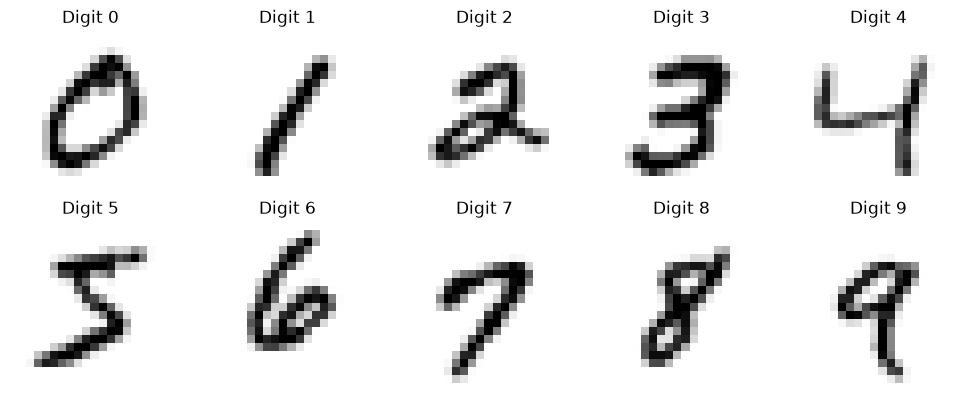

In [26]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for digit, ax in enumerate(axes.flat):
    index = (train_labels == digit).nonzero(as_tuple=True)[0][0].item()
    image = train_images[index]

    # Remove a single channel dimension for plotting if present.
    if image.ndim == 3 and image.shape[0] == 1:
        image = image.squeeze(0)

    ax.imshow(image.cpu(), cmap="gray")
    ax.set_title(f"Digit {digit}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### 2.4 Scale Images

In [27]:
# Scale image values from [0, 1] to [-1, 1].
train_images_scaled = train_images * 2.0 - 1.0
test_images_scaled = test_images * 2.0 - 1.0

print(
    f"Train range: "
    f"[{train_images_scaled.min().item():.1f}, "
    f"{train_images_scaled.max().item():.1f}]"
)

print(
    f"Test range:  "
    f"[{test_images_scaled.min().item():.1f}, "
    f"{test_images_scaled.max().item():.1f}]"
)

print(f"Train shape: {tuple(train_images_scaled.shape)}")
print(f"Test shape:  {tuple(test_images_scaled.shape)}")

Train range: [-1.0, 1.0]
Test range:  [-1.0, 1.0]
Train shape: (60000, 1, 20, 20)
Test shape:  (10000, 1, 20, 20)


### 2.5 Build Datasets / loaders

In [28]:
train_dataset = TensorDataset(
    train_images_scaled,
    train_labels
)

test_dataset = TensorDataset(
    test_images_scaled,
    test_labels
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print(f"Training samples: {len(train_dataset):,}")
print(f"Testing samples:  {len(test_dataset):,}")
print(f"Training batches: {len(train_loader):,}")
print(f"Testing batches:  {len(test_loader):,}")

Training samples: 60,000
Testing samples:  10,000
Training batches: 469
Testing batches:  79


verify one batch

In [29]:
batch_images, batch_labels = next(iter(train_loader))

print(f"Image batch shape: {batch_images.shape}")
print(f"Label batch shape: {batch_labels.shape}")
print(f"Image dtype:       {batch_images.dtype}")
print(f"Label dtype:       {batch_labels.dtype}")
print(
    f"Image range:       "
    f"[{batch_images.min().item():.1f}, "
    f"{batch_images.max().item():.1f}]"
)

Image batch shape: torch.Size([128, 1, 20, 20])
Label batch shape: torch.Size([128])
Image dtype:       torch.float32
Label dtype:       torch.int64
Image range:       [-1.0, 1.0]


## 3. Linear Noise Schedule

The DDPM forward process progressively corrupts a clean image $x_0$ by adding Gaussian noise over $T$ diffusion time steps.

At each timestep, the variance schedule defines a noise value $\beta_t$. From this:

$$
\alpha_t = 1 - \beta_t
$$

and the cumulative product

$$
\bar{\alpha}_t = \prod_{s=1}^{t}\alpha_s
$$

describes how much of the original signal remains at timestep $t$.

The Week 9 tutorial uses a **linear beta schedule**, in which $\beta_t$ increases linearly from a small starting value to a larger final value. This schedule is retained as the baseline for Project 7.

In [31]:
# CITE: TUTORIAL 9 SOLUTION
timesteps = 1000

def linear_beta_schedule(timesteps, beta_start=1e-4, beta_end=0.02):
    return torch.linspace(beta_start,beta_end, timesteps)

linear_betas = linear_beta_schedule(timesteps).to(device)
linear_alphas = 1.0 - linear_betas
linear_alpha_bars = torch.cumprod(linear_alphas, dim=0)

## 4. Cosine Noise Schedule

The second DDPM uses a **cosine noise schedule** rather than the linear schedule used by the tutorial baseline.

Instead of defining $\beta_t$ directly as a linear sequence, the cosine schedule first defines the cumulative signal retention $\bar{\alpha}_t$ using a cosine function. The corresponding $\beta_t$ values are then derived from consecutive cumulative values.

The schedule is defined as:

$$
\bar{\alpha}_t =
\frac{
\cos^2\left(
\frac{t/T+s}{1+s}\frac{\pi}{2}
\right)
}{
\cos^2\left(
\frac{s}{1+s}\frac{\pi}{2}
\right)
}
$$

where $T$ is the total number of diffusion timesteps and $s$ is a small offset.

The resulting beta values are obtained from:

$$
\beta_t =
1 -
\frac{\bar{\alpha}_t}
{\bar{\alpha}_{t-1}}
$$

and clipped to prevent numerically problematic values close to 1.

This changes how quickly information is removed from the original image across diffusion time while leaving the underlying DDPM training objective unchanged.

In [32]:
def cosine_beta_schedule(timesteps, s=0.008):
    """
    Create a cosine beta schedule for DDPM.

    The schedule defines alpha_bar using a cosine function and derives
    beta_t from the ratio between consecutive alpha_bar values.
    """
    steps = timesteps + 1
    x = torch.linspace(0, timesteps, steps)

    alpha_bars = torch.cos(
        ((x / timesteps + s) / (1 + s)) * torch.pi / 2
    ) ** 2

    # Normalise so alpha_bar starts at 1.
    alpha_bars = alpha_bars / alpha_bars[0]

    betas = 1.0 - (alpha_bars[1:] / alpha_bars[:-1])

    # Avoid beta values reaching 1.
    return torch.clamp(betas, min=1e-4, max=0.999)


cosine_betas = cosine_beta_schedule(timesteps).to(device)
cosine_alphas = 1.0 - cosine_betas
cosine_alpha_bars = torch.cumprod(cosine_alphas, dim=0)

### 4.1 validate the schedulers

In [33]:
print("Linear schedule")
print(f"  Shape:          {linear_betas.shape}")
print(f"  Beta range:     {linear_betas.min().item():.6f} to "
      f"{linear_betas.max().item():.6f}")
print(f"  Final alpha_bar: {linear_alpha_bars[-1].item():.8f}")

print("\nCosine schedule")
print(f"  Shape:          {cosine_betas.shape}")
print(f"  Beta range:     {cosine_betas.min().item():.6f} to "
      f"{cosine_betas.max().item():.6f}")
print(f"  Final alpha_bar: {cosine_alpha_bars[-1].item():.8f}")

assert linear_betas.shape == cosine_betas.shape
assert torch.all(linear_betas > 0)
assert torch.all(linear_betas < 1)
assert torch.all(cosine_betas > 0)
assert torch.all(cosine_betas < 1)

print("\nSchedule validation passed.")

Linear schedule
  Shape:          torch.Size([1000])
  Beta range:     0.000100 to 0.020000
  Final alpha_bar: 0.00004036

Cosine schedule
  Shape:          torch.Size([1000])
  Beta range:     0.000100 to 0.999000
  Final alpha_bar: 0.00000000

Schedule validation passed.


## 5. Visualise and Validate the Noise Schedules

Before training, the linear and cosine schedules are compared to verify how they distribute noise across the 1,000-step forward diffusion process.

Two quantities are examined:

- $\beta_t$, which controls the amount of noise introduced at each diffusion step; and
- $\bar{\alpha}_t$, which represents the cumulative proportion of the original signal retained as diffusion progresses.

This comparison verifies that the two models will use meaningfully different noise trajectories while retaining the same total number of diffusion timesteps.

### 5.1 Comapre beta schedules

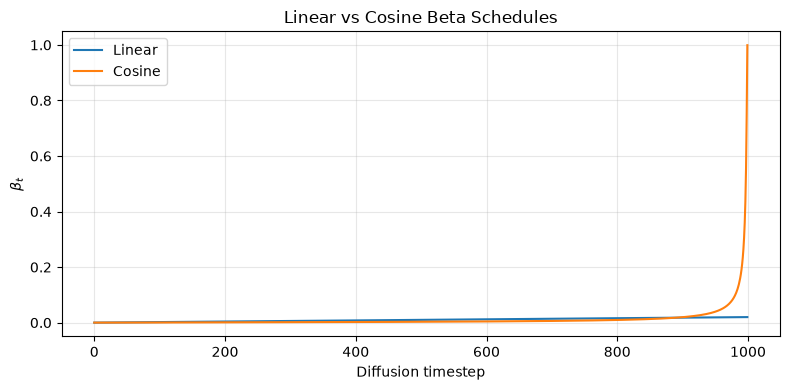

In [34]:
# Move schedule values to CPU for plotting.
t = np.arange(timesteps)

plt.figure(figsize=(8, 4))

plt.plot(t, linear_betas.detach().cpu(), label="Linear")
plt.plot(t, cosine_betas.detach().cpu(), label="Cosine")

plt.xlabel("Diffusion timestep")
plt.ylabel(r"$\beta_t$")
plt.title("Linear vs Cosine Beta Schedules")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 5.2 Compare cumulative signal retention

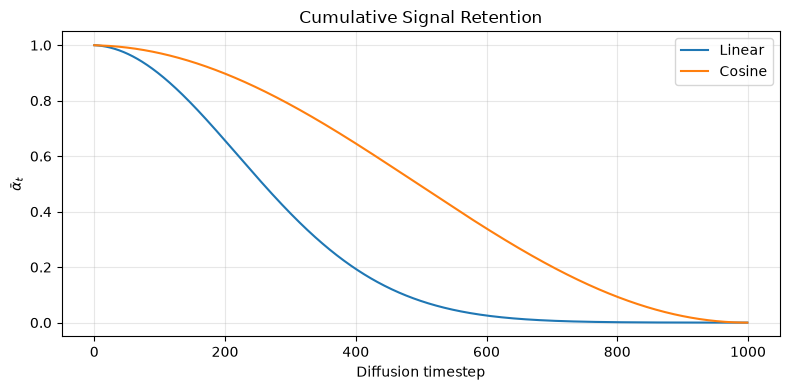

In [35]:
plt.figure(figsize=(8, 4))

plt.plot(
    t,
    linear_alpha_bars.detach().cpu(),
    label="Linear"
)

plt.plot(
    t,
    cosine_alpha_bars.detach().cpu(),
    label="Cosine"
)

plt.xlabel("Diffusion timestep")
plt.ylabel(r"$\bar{\alpha}_t$")
plt.title("Cumulative Signal Retention")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 5.3 Numerical checks
alpha_bar must monotonically decrease.

In [37]:
def validate_schedule(name, betas, alpha_bars):
    assert len(betas) == timesteps
    assert len(alpha_bars) == timesteps

    assert torch.all(torch.isfinite(betas))
    assert torch.all(torch.isfinite(alpha_bars))

    assert torch.all((betas > 0) & (betas < 1))
    assert torch.all(alpha_bars[1:] <= alpha_bars[:-1])

    print(
        f"{name:<8} | "
        f"alpha_bar start: {alpha_bars[0].item():.6f} | "
        f"alpha_bar end: {alpha_bars[-1].item():.8f}"
    )


validate_schedule(
    "Linear",
    linear_betas,
    linear_alpha_bars
)

validate_schedule(
    "Cosine",
    cosine_betas,
    cosine_alpha_bars
)

print("\nBoth schedules passed validation.")

Linear   | alpha_bar start: 0.999900 | alpha_bar end: 0.00004036
Cosine   | alpha_bar start: 0.999900 | alpha_bar end: 0.00000000

Both schedules passed validation.


## 6. Shared Forward Diffusion

The DDPM forward process constructs a noisy sample $x_t$ directly from a clean image $x_0$ using:

$$
x_t =
\sqrt{\bar{\alpha}_t}x_0
+
\sqrt{1-\bar{\alpha}_t}\epsilon,
\qquad
\epsilon \sim \mathcal{N}(0,I)
$$

where $\bar{\alpha}_t$ is determined by the selected noise schedule.

The same forward-diffusion implementation is shared by both Project 7 models. Only the schedule coefficients supplied to the function differ between the linear and cosine experiments.

This maintains the noise schedule as the primary experimental variable.

In [38]:
# Precompute coefficients required for forward diffusion.

linear_sqrt_alpha_bars = torch.sqrt(linear_alpha_bars)
linear_sqrt_one_minus_alpha_bars = torch.sqrt(
    1.0 - linear_alpha_bars
)

cosine_sqrt_alpha_bars = torch.sqrt(cosine_alpha_bars)
cosine_sqrt_one_minus_alpha_bars = torch.sqrt(
    1.0 - cosine_alpha_bars
)

print("Forward diffusion coefficients prepared.")
print(f"Linear coefficient shape: {linear_sqrt_alpha_bars.shape}")
print(f"Cosine coefficient shape: {cosine_sqrt_alpha_bars.shape}")

Forward diffusion coefficients prepared.
Linear coefficient shape: torch.Size([1000])
Cosine coefficient shape: torch.Size([1000])


### 6.1 Extracting timestep coefficients

During training, each image in a batch may be assigned a different diffusion timestep.

The `extract` helper selects the corresponding schedule coefficient for each sample and reshapes the result so that it can be broadcast across the image dimensions.

In [39]:
# ADAPTED FROM: TUTORIAL 9 SOLUTION
def extract(values, timesteps_batch, x_shape):
    batch_size = timesteps_batch.shape[0]

    out = values.gather(0, timesteps_batch)

    return out.reshape(
        batch_size,
        *((1,) * (len(x_shape) - 1))
    )

### 6.2 Shared forward sampling

The tutorial forward-sampling process is adapted so that schedule coefficients are supplied explicitly.

This allows the same `q_sample` implementation to be used for both the linear and cosine DDPMs without duplicating the diffusion logic.

In [40]:
def q_sample(
    x_start,
    t,
    sqrt_alpha_bars,
    sqrt_one_minus_alpha_bars,
    noise=None
):
    if noise is None:
        noise = torch.randn_like(x_start)

    sqrt_alpha_bar_t = extract(
        sqrt_alpha_bars,
        t,
        x_start.shape
    )

    sqrt_one_minus_alpha_bar_t = extract(
        sqrt_one_minus_alpha_bars,
        t,
        x_start.shape
    )

    x_noisy = (
        sqrt_alpha_bar_t * x_start
        + sqrt_one_minus_alpha_bar_t * noise
    )

    return x_noisy, noise

TEst Shared Forward diffusion

In [41]:
sample_images, sample_labels = next(iter(train_loader))

sample_images = sample_images[:8].to(device)

sample_t = torch.full(
    (sample_images.shape[0],),
    500,
    device=device,
    dtype=torch.long
)

linear_noisy, _ = q_sample(
    sample_images,
    sample_t,
    linear_sqrt_alpha_bars,
    linear_sqrt_one_minus_alpha_bars
)

cosine_noisy, _ = q_sample(
    sample_images,
    sample_t,
    cosine_sqrt_alpha_bars,
    cosine_sqrt_one_minus_alpha_bars
)

print(f"Original: {sample_images.shape}")
print(f"Linear:   {linear_noisy.shape}")
print(f"Cosine:   {cosine_noisy.shape}")

assert linear_noisy.shape == sample_images.shape
assert cosine_noisy.shape == sample_images.shape
assert torch.all(torch.isfinite(linear_noisy))
assert torch.all(torch.isfinite(cosine_noisy))

print("\nForward diffusion validation passed.")

Original: torch.Size([8, 1, 20, 20])
Linear:   torch.Size([8, 1, 20, 20])
Cosine:   torch.Size([8, 1, 20, 20])

Forward diffusion validation passed.


### 6.3 Forward-process comparison

To visualise the effect of the two schedules, the same clean image is diffused at selected timesteps using both the linear and cosine coefficients.

The same Gaussian noise is reused for corresponding linear and cosine samples so that differences in the resulting images are attributable to the noise schedule rather than different random noise draws.

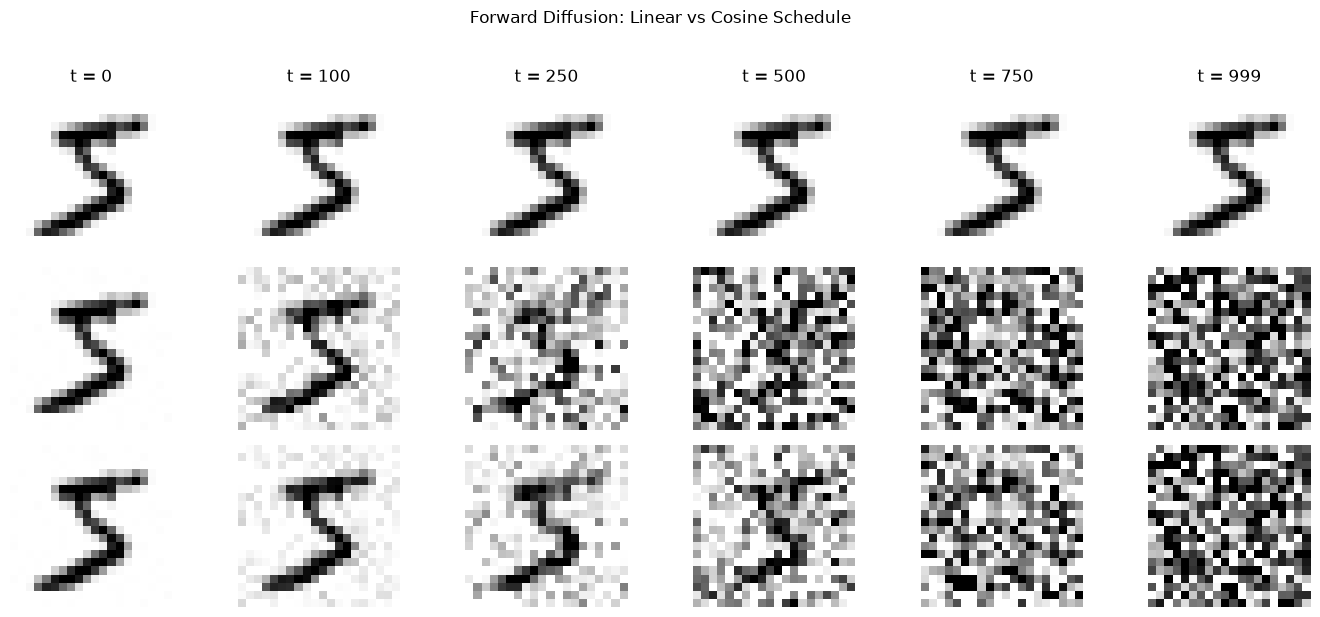

In [42]:
# Select one example image.
x_start = train_images_scaled[0:1].to(device)

comparison_timesteps = [0, 100, 250, 500, 750, 999]

# Use the same noise for both schedules at each timestep.
torch.manual_seed(SEED)

fig, axes = plt.subplots(
    3,
    len(comparison_timesteps),
    figsize=(14, 6)
)

for col, timestep in enumerate(comparison_timesteps):
    t = torch.tensor(
        [timestep],
        device=device,
        dtype=torch.long
    )

    shared_noise = torch.randn_like(x_start)

    linear_noisy, _ = q_sample(
        x_start,
        t,
        linear_sqrt_alpha_bars,
        linear_sqrt_one_minus_alpha_bars,
        noise=shared_noise
    )

    cosine_noisy, _ = q_sample(
        x_start,
        t,
        cosine_sqrt_alpha_bars,
        cosine_sqrt_one_minus_alpha_bars,
        noise=shared_noise
    )

    # Original
    axes[0, col].imshow(
        x_start[0, 0].detach().cpu(),
        cmap="gray",
        vmin=-1,
        vmax=1
    )

    # Linear
    axes[1, col].imshow(
        linear_noisy[0, 0].detach().cpu(),
        cmap="gray",
        vmin=-1,
        vmax=1
    )

    # Cosine
    axes[2, col].imshow(
        cosine_noisy[0, 0].detach().cpu(),
        cmap="gray",
        vmin=-1,
        vmax=1
    )

    axes[0, col].set_title(f"t = {timestep}")

for ax in axes.flat:
    ax.axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Linear")
axes[2, 0].set_ylabel("Cosine")

plt.suptitle(
    "Forward Diffusion: Linear vs Cosine Schedule",
    y=1.02
)

plt.tight_layout()
plt.show()

### 6.4 (CleanUp) Shared Schedule Representation

The forward and reverse DDPM processes require several coefficients derived from the selected beta schedule.

To avoid maintaining separate linear and cosine versions of each coefficient, a shared helper constructs the required diffusion values from any supplied sequence of beta values.

The resulting schedule dictionaries allow the remaining DDPM implementation to be independent of the schedule type. The linear and cosine models therefore use the same forward diffusion, model architecture and training logic, with only their schedule coefficients differing.

In [43]:
def prepare_diffusion_coefficients(betas):
    """
    Precompute coefficients required by the DDPM forward and reverse processes.
    """
    alphas = 1.0 - betas
    alpha_bars = torch.cumprod(alphas, dim=0)

    return {
        "betas": betas,
        "alphas": alphas,
        "alpha_bars": alpha_bars,

        # Forward diffusion coefficients
        "sqrt_alpha_bars": torch.sqrt(alpha_bars),
        "sqrt_one_minus_alpha_bars": torch.sqrt(1.0 - alpha_bars),

        # Reverse diffusion coefficients
        "sqrt_recip_alphas": torch.sqrt(1.0 / alphas),
    }


linear_schedule = prepare_diffusion_coefficients(linear_betas)
cosine_schedule = prepare_diffusion_coefficients(cosine_betas)

#### validate this new data structure

In [44]:
print("Linear schedule:")
for key, value in linear_schedule.items():
    print(f"  {key:<30} {tuple(value.shape)}")

print("\nCosine schedule:")
for key, value in cosine_schedule.items():
    print(f"  {key:<30} {tuple(value.shape)}")


assert linear_schedule.keys() == cosine_schedule.keys()

for schedule in (linear_schedule, cosine_schedule):
    for name, values in schedule.items():
        assert values.shape == (timesteps,), (
            f"Unexpected shape for {name}: {values.shape}"
        )
        assert torch.all(torch.isfinite(values)), (
            f"Non-finite values found in {name}"
        )

print("\nShared schedule representation validated.")

Linear schedule:
  betas                          (1000,)
  alphas                         (1000,)
  alpha_bars                     (1000,)
  sqrt_alpha_bars                (1000,)
  sqrt_one_minus_alpha_bars      (1000,)
  sqrt_recip_alphas              (1000,)

Cosine schedule:
  betas                          (1000,)
  alphas                         (1000,)
  alpha_bars                     (1000,)
  sqrt_alpha_bars                (1000,)
  sqrt_one_minus_alpha_bars      (1000,)
  sqrt_recip_alphas              (1000,)

Shared schedule representation validated.
